# TTC — figure per la tesi

Salva il notebook in grafici/, accanto a plot_utils.py. Usa results/brt/ttc.npz e gli script del progetto.

Le due figure principali mostrano l’isosuperficie 3D a sinistra e tre fette XY a destra. Gli angoli si scelgono in THETA_VALUES; velocità e sterzo sono fissati nella configurazione. I mosaici 3×3 delle velocità mantengono la struttura precedente.

**Tutti gli export sono attivi (SALVA = True): Esegui tutto salva i quattro grafici PDF/EPS e sovrascrive quelli omonimi.**


**Rigenerazione:** i dati restano in `results/brt/<metrica>.npz`. Eseguire il notebook dall’inizio con Restart Kernel / Run All. Le anteprime precedenti sono state svuotate per evitare figure obsolete. Tutte le colorbar mostrano due decimali; i parametri fissi sono da specificare nelle caption.

## V₀ — isosuperficie 3D e fette al variare di θ relativo


Input: /home/alessio-grisorio/TESI/hj_reachability/results/brt/ttc.npz
Campo: V0; v_E=6, v_H=6, delta_E=0 rad


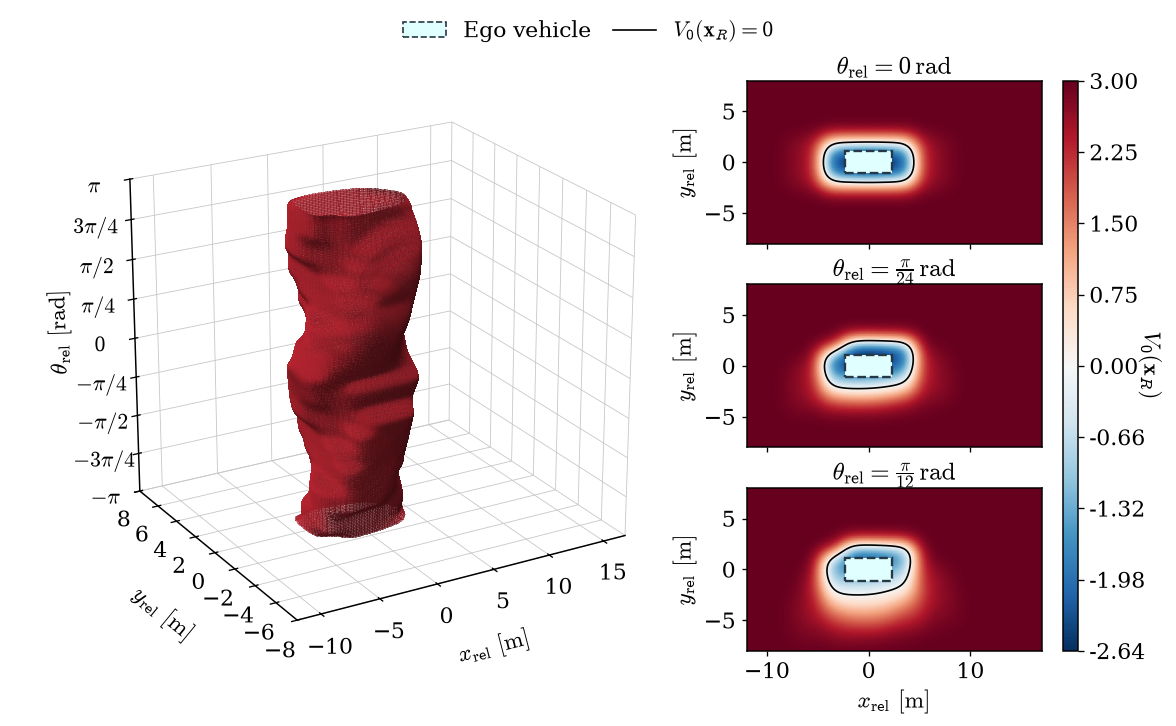

In [23]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from plot_utils import set_style, export_figure, finish_figure

set_style()


# Individua la radice del repository.
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "scripts" / "plot_terminal_value.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Apri il notebook all'interno del repository hj_reachability."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts import plot_terminal_value as terminal
from scripts import compare_terminal_values as comparison


# ---------------- Configurazione ----------------

METRIC = "ttc"
DATA_DIRECTORY = ROOT / "results" / "brt"

V_E = 6.0
V_H = 6.0
DELTA_E = 0.0

X_LIMITS = None
Y_LIMITS = None
THETA_LIMITS = (-np.pi , np.pi )

FIGURE_SIZE = (12.0, 5.0)
ELEVATION = 22
AZIMUTH = -120

COLORMAP = "jet"
COLOR_LIMITS = None
SCATTER_STRIDE = (1, 1, 2)
SCATTER_SIZE = 5.0

SURFACE_COLOR = plt.get_cmap("RdBu_r")(0.88)
SURFACE_ALPHA = 0.5
SURFACE_REFINEMENT = 4
SMOOTHING_SIGMA = 2.0

# ------------------------------------------------


from fractions import Fraction
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter
from scripts.plot_terminal_slices import bracket

# Tre fette XY a velocità e sterzo fissati.
THETA_VALUES = (0.0, np.pi / 24, np.pi / 12)  # Tre fette selezionabili.
ANGLE_FIGURE_SIZE = (9.6, 5.8)
ANGLE_REFINEMENT = 6
ANGLE_SMOOTHING = 5.0
ANGLE_COLORMAP = "RdBu_r"


def format_angle(angle):
    ratio = Fraction(float(angle/np.pi)).limit_denominator(24)
    if not np.isclose(float(ratio)*np.pi, angle, rtol=0, atol=1e-9):
        return f"{angle:.3g}"
    n, d = ratio.numerator, ratio.denominator
    if n == 0:
        return "0"
    sign = "-" if n < 0 else ""
    top = r"\pi" if abs(n) == 1 else rf"{abs(n)}\pi"
    return sign + top if d == 1 else rf"{sign}\frac{{{top}}}{{{d}}}"


def make_angle_figure(field_key):
    if len(THETA_VALUES) != 3:
        raise ValueError("Scegliere esattamente tre angoli.")
    if int(ANGLE_REFINEMENT) != ANGLE_REFINEMENT or ANGLE_REFINEMENT < 1:
        raise ValueError("Il raffinamento deve essere un intero positivo.")
    if ANGLE_SMOOTHING < 0:
        raise ValueError("Lo smoothing deve essere >= 0.")

    terminal.KEY = field_key
    terminal.DATA_DIRECTORY = DATA_DIRECTORY
    terminal.INPUT_FILE = None
    terminal.V_E, terminal.V_H, terminal.DELTA_E = V_E, V_H, DELTA_E
    terminal.X_LIMITS, terminal.Y_LIMITS = X_LIMITS, Y_LIMITS
    terminal.THETA_LIMITS = THETA_LIMITS
    terminal.ELEVATION, terminal.AZIMUTH = ELEVATION, AZIMUTH

    grid_axes, field, label = terminal.load_slice(METRIC)
    _, _, domain = terminal.prepare_domain(grid_axes, field)
    fields = {field_key: field}
    if field_key == "BRT":
        terminal.KEY = "V0"
        try:
            initial_axes, initial, _ = terminal.load_slice(METRIC)
        finally:
            terminal.KEY = field_key
        if any(not np.array_equal(a, b) for a, b in zip(grid_axes, initial_axes)):
            raise ValueError("Griglie V0 e BRT diverse.")
        fields["V0"] = initial

    comparison.V_E_3D = V_E
    comparison.V_H = V_H
    comparison.DELTA_E = DELTA_E
    comparison.SURFACE_ALPHA = SURFACE_ALPHA
    comparison.SURFACE_REFINEMENT = SURFACE_REFINEMENT
    comparison.SMOOTHING_SIGMA = SMOOTHING_SIGMA

    x, y, theta = grid_axes
    fine_axes = [
        np.linspace(a[0], a[-1], (len(a)-1)*int(ANGLE_REFINEMENT)+1)
        for a in (x, y)
    ]
    points = np.stack(np.meshgrid(*fine_axes, indexing="ij"), axis=-1)
    crop_axes = [
        np.unique(np.r_[lo, a[(a > lo) & (a < hi)], hi])
        for a, (lo, hi) in zip(fine_axes, domain[:2])
    ]
    crop_points = np.stack(np.meshgrid(*crop_axes, indexing="ij"), axis=-1)
    slices = {}
    for key, volume in fields.items():
        slices[key] = []
        for angle in THETA_VALUES:
            lo, hi, w = bracket(theta, angle, "theta_rel", periodic=True)
            section = (1-w)*volume[:, :, lo] + w*volume[:, :, hi]
            fine = RegularGridInterpolator((x, y), section)(points)
            if ANGLE_SMOOTHING:
                fine = gaussian_filter(fine, sigma=ANGLE_SMOOTHING, mode="nearest")
            plotted = RegularGridInterpolator(tuple(fine_axes), fine)(crop_points)
            if not np.isfinite(plotted).all():
                raise ValueError("Fetta con NaN o infiniti.")
            slices[key].append(plotted)
    low = min(float(s.min()) for s in slices[field_key])
    high = max(float(s.max()) for s in slices[field_key])
    if low >= high:
        raise ValueError("Colorbar degenere.")
    norm = (TwoSlopeNorm(vmin=low, vcenter=0, vmax=high)
            if low < 0 < high else Normalize(vmin=low, vmax=high))

    set_style()
    fig = plt.figure(figsize=ANGLE_FIGURE_SIZE, layout="none")
    # Dimensioni fisiche: ogni fetta mantiene la scala spaziale 1:1.
    fig_width, fig_height = fig.get_size_inches()
    bottom_in, top_in, row_gap_in = 0.43, 0.62, 0.34
    body_height = fig_height - bottom_in - top_in
    slice_height = (body_height - 2*row_gap_in) / 3
    xy_ratio = (domain[1][1]-domain[1][0]) / (domain[0][1]-domain[0][0])
    slice_width = slice_height / xy_ratio
    bar_width, bar_gap, right_margin = 0.12, 0.18, 0.72
    bar_x = fig_width - right_margin - bar_width
    slice_x = bar_x - bar_gap - slice_width
    spatial_left, middle_gap = 0.38, 0.52
    spatial_width = slice_x - middle_gap - spatial_left
    if min(body_height, slice_height, spatial_width) <= 0:
        raise ValueError("Figsize troppo piccola per la disposizione richiesta.")

    header = fig.add_axes([0, (fig_height-0.37)/fig_height, 1, 0.32/fig_height])
    header.set_axis_off()
    handles = [
        Patch(facecolor="lightcyan", edgecolor="#263746", linestyle="--",
              label="Ego vehicle"),
        Line2D([], [], color="black", linewidth=1, label="$"+label+"=0$"),
    ]
    if field_key == "BRT":
        handles.append(Line2D(
            [], [], color="#287a32", linestyle="--", linewidth=1.4,
            label=r"$V_0(\mathbf{x}_R)=0$",
        ))
    # Parametri fissi dichiarati nella caption.
    header.legend(handles=handles, loc="center", ncol=len(handles),
                  frameon=False, handlelength=2, columnspacing=1.0)

    spatial = fig.add_axes(
        [spatial_left/fig_width, bottom_in/fig_height,
         spatial_width/fig_width, body_height/fig_height],
        projection="3d",
    )
    terminal.configure_axis(spatial, domain)
    spatial.tick_params(labelsize=plt.rcParams["xtick.labelsize"])
    spatial.set_box_aspect((1.1, 1, 1), zoom=1.04)
    surface_axes = [*grid_axes, np.array([V_H]), np.array([DELTA_E]), np.array([V_E])]
    comparison.plot_surface(
        spatial, surface_axes, field[..., None, None, None],
        SURFACE_COLOR, METRIC, domain,
    )

    panels = []
    for row, (section, angle) in enumerate(zip(slices[field_key], THETA_VALUES)):
        slice_y = bottom_in + (2-row)*(slice_height+row_gap_in)
        ax = fig.add_axes(
            [slice_x/fig_width, slice_y/fig_height,
             slice_width/fig_width, slice_height/fig_height],
            sharex=panels[0] if panels else None,
            sharey=panels[0] if panels else None,
        )
        panels.append(ax)
        image = ax.pcolormesh(
            *crop_axes, section.T, shading="gouraud",
            cmap=ANGLE_COLORMAP, norm=norm, rasterized=True,
        )
        if section.min() < 0 < section.max():
            ax.contour(*crop_axes, section.T, levels=[0], colors="black", linewidths=1)
        if field_key == "BRT":
            initial = slices["V0"][row]
            if initial.min() < 0 < initial.max():
                ax.contour(
                    *crop_axes, initial.T, levels=[0], colors="#287a32",
                    linewidths=1.4, linestyles="--", zorder=4,
                )
        ax.add_patch(Rectangle(
            (-4.68/2, -2.20/2), 4.68, 2.20,
            facecolor="lightcyan", edgecolor="#263746",
            linewidth=1.4, linestyle="--", zorder=5,
        ))
        ax.set_xlim(domain[0])
        ax.set_ylim(domain[1])
        ax.set_aspect("equal", adjustable="box")
        ax.set_ylabel(r"$y_{\mathrm{rel}}\ [\mathrm{m}]$")
        ax.set_title(rf"$\theta_{{\mathrm{{rel}}}}={format_angle(angle)}\,\mathrm{{rad}}$",
                     pad=4)
        ax.tick_params(labelbottom=(row == 2), direction="out", length=3)
        if row == 2:
            ax.set_xlabel(r"$x_{\mathrm{rel}}\ [\mathrm{m}]$")
    cax = fig.add_axes([
        bar_x/fig_width, bottom_in/fig_height,
        bar_width/fig_width, body_height/fig_height,
    ])
    bar = fig.colorbar(image, cax=cax)
    ticks = (np.r_[np.linspace(low, 0, 5), np.linspace(0, high, 5)[1:]]
             if low < 0 < high else np.linspace(low, high, 7))
    bar.set_ticks(ticks)
    bar.set_ticklabels([f"{v:.2f}" for v in ticks])
    bar.set_label("$"+label+"$", labelpad=9)
    return fig


fig_v0 = make_angle_figure("V0")
finish_figure(plt.gcf())
plt.show()



In [24]:
# Imposta True ed esegui questa cella per esportare.
SALVA = True

if SALVA:
    export_figure(
        fig_v0,
        nome="ttc_v0",
        cartella=METRIC,
        formati=("pdf", "eps"),
        sovrascrivi=True,
    )


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_v0.pdf


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as uni

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_v0.eps


## V₀ — mosaico 3×3

Colonne: velocità ego. Righe: velocità human. Colorbar comune; θ relativo e sterzo sono fissati.

Vista precedente: export con suffisso `_old`. Il mosaico aggiornato è nella sezione finale.

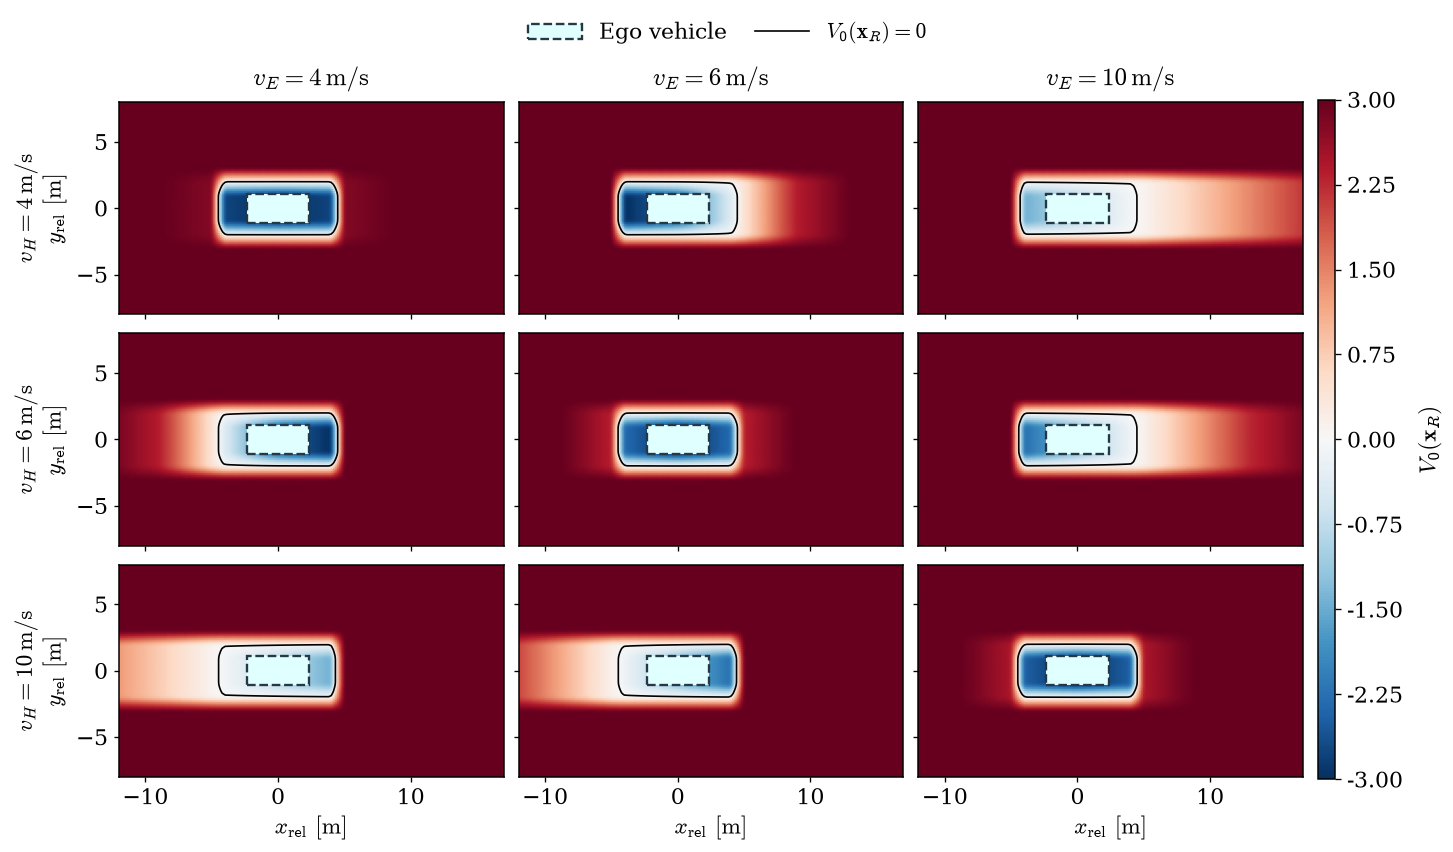

In [25]:
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter
from scripts.plot_terminal_slices import bracket

# Colonne: velocità ego; righe: velocità human.
V_E_VALUES = (4.0, 6.0, 10.0)
V_H_VALUES = (4.0, 6.0, 10.0)
THETA_MOSAIC = 0.0
DELTA_MOSAIC = 0.0
MOSAIC_SIZE = (12.0, 7.0)
MOSAIC_X_LIMITS = None
MOSAIC_Y_LIMITS = None
MOSAIC_REFINEMENT = 6
MOSAIC_SMOOTHING = 0.8
MOSAIC_COLORMAP = "RdBu_r"


def make_speed_mosaic(field_key):
    """Crea il mosaico senza esportarlo."""
    if len(V_E_VALUES) != 3 or len(V_H_VALUES) != 3:
        raise ValueError("Specificare tre velocità ego e tre velocità human.")
    if int(MOSAIC_REFINEMENT) != MOSAIC_REFINEMENT or MOSAIC_REFINEMENT < 1:
        raise ValueError("Raffinamento intero positivo richiesto.")
    if MOSAIC_SMOOTHING < 0:
        raise ValueError("Lo smoothing deve essere >= 0.")
    names = ("x_rel", "y_rel", "theta_rel", "v_H", "delta_E", "v_E")
    rendered = {}
    with np.load(DATA_DIRECTORY / f"{METRIC}.npz", allow_pickle=False) as data:
        grid_axes = [np.asarray(data[n], dtype=float) for n in names]
        if "state_names" in data and tuple(data["state_names"].tolist()) != names:
            raise ValueError("Ordine degli stati incompatibile.")
        for name, axis in zip(names, grid_axes):
            if (axis.ndim != 1 or len(axis) < 1 or not np.isfinite(axis).all()
                    or not np.all(np.diff(axis) > 0)):
                raise ValueError(f"Asse non valido: {name}")
        time = float(data["target_time"]) if field_key == "BRT" else None
        x, y = grid_axes[:2]
        limits_xy = [
            MOSAIC_X_LIMITS if MOSAIC_X_LIMITS is not None else (x[0], x[-1]),
            MOSAIC_Y_LIMITS if MOSAIC_Y_LIMITS is not None else (y[0], y[-1]),
        ]
        for axis, (lo, hi) in zip((x, y), limits_xy):
            if lo >= hi or lo < axis[0] or hi > axis[-1]:
                raise ValueError("Limiti spaziali fuori dal dominio.")
        fine_axes = [
            np.linspace(a[0], a[-1], (len(a)-1)*int(MOSAIC_REFINEMENT)+1)
            for a in (x, y)
        ]
        fine_points = np.stack(np.meshgrid(*fine_axes, indexing="ij"), axis=-1)
        crop_axes = [
            np.unique(np.r_[lo, a[(a > lo) & (a < hi)], hi])
            for a, (lo, hi) in zip(fine_axes, limits_xy)
        ]
        crop_points = np.stack(np.meshgrid(*crop_axes, indexing="ij"), axis=-1)
        for key in (("BRT", "V0") if field_key == "BRT" else ("V0",)):
            field = data[key]
            if field.shape != tuple(len(a) for a in grid_axes):
                raise ValueError(f"Forma incompatibile: {key}")
            rendered[key] = []
            for vh in V_H_VALUES:
                for ve in V_E_VALUES:
                    section = field
                    for dim, value in (
                        (5, ve), (4, DELTA_MOSAIC), (3, vh), (2, THETA_MOSAIC),
                    ):
                        lo, hi, w = bracket(
                            grid_axes[dim], value, names[dim], periodic=(dim == 2)
                        )
                        section = ((1-w)*np.take(section, lo, axis=dim)
                                   + w*np.take(section, hi, axis=dim))
                    fine = RegularGridInterpolator((x, y), section)(fine_points)
                    if MOSAIC_SMOOTHING:
                        fine = gaussian_filter(fine, sigma=MOSAIC_SMOOTHING, mode="nearest")
                    plotted = RegularGridInterpolator(tuple(fine_axes), fine)(crop_points)
                    if not np.isfinite(plotted).all():
                        raise ValueError("Fetta con NaN o infiniti.")
                    rendered[key].append(plotted)
            del field, section

    sections = rendered[field_key]
    lower = min(float(s.min()) for s in sections)
    upper = max(float(s.max()) for s in sections)
    if lower >= upper:
        raise ValueError("Colorbar degenere.")
    norm = (TwoSlopeNorm(vmin=lower, vcenter=0.0, vmax=upper)
            if lower < 0 < upper else Normalize(vmin=lower, vmax=upper))
    label = (rf"V({time:g},\mathbf{{x}}_R)"
             if field_key == "BRT" else r"V_0(\mathbf{x}_R)")
    set_style()
    fig = plt.figure(figsize=MOSAIC_SIZE, layout="constrained")
    grid = fig.add_gridspec(
        4, 4, width_ratios=(1, 1, 1, 0.045), height_ratios=(0.20, 1, 1, 1),
    )
    header = fig.add_subplot(grid[0, :])
    header.set_axis_off()
    handles = [
        Patch(facecolor="lightcyan", edgecolor="#263746",
              linewidth=1.4, linestyle="--", label="Ego vehicle"),
        Line2D([], [], color="black", linewidth=1.0, label="$"+label+"=0$"),
    ]
    if field_key == "BRT":
        handles.append(Line2D(
            [], [], color="#287a32", linewidth=1.4, linestyle="--",
            label=r"$V_0(\mathbf{x}_R)=0$",
        ))
    # Parametri fissi dichiarati nella caption.
    header.legend(
        handles=handles, loc="center", ncol=len(handles),
        frameon=False, handlelength=2.5, columnspacing=1.3,
    )
    panels = []
    for index, section in enumerate(sections):
        row, column = divmod(index, 3)
        ax = fig.add_subplot(
            grid[row+1, column],
            sharex=panels[0] if panels else None,
            sharey=panels[0] if panels else None,
        )
        panels.append(ax)
        image = ax.pcolormesh(
            *crop_axes, section.T, shading="gouraud",
            cmap=MOSAIC_COLORMAP, norm=norm, rasterized=True,
        )
        if section.min() < 0 < section.max():
            ax.contour(*crop_axes, section.T, levels=[0], colors="black", linewidths=1.0)
        if field_key == "BRT":
            initial = rendered["V0"][index]
            if initial.min() < 0 < initial.max():
                ax.contour(
                    *crop_axes, initial.T, levels=[0], colors="#287a32",
                    linewidths=1.4, linestyles="--", zorder=4,
                )
        ax.add_patch(Rectangle(
            (-4.68/2, -2.20/2), 4.68, 2.20,
            facecolor="lightcyan", edgecolor="#263746",
            linewidth=1.4, linestyle="--", zorder=5,
        ))
        ax.set_xlim(limits_xy[0])
        ax.set_ylim(limits_xy[1])
        ax.set_aspect("equal", adjustable="box")
        ax.tick_params(direction="out", length=3,
                       labelbottom=(row == 2), labelleft=(column == 0))
        if row == 2:
            ax.set_xlabel(r"$x_{\mathrm{rel}}\ [\mathrm{m}]$")
        if column == 0:
            ax.set_ylabel(
                rf"$v_H={V_H_VALUES[row]:g}\,\mathrm{{m/s}}$"
                "\n" r"$y_{\mathrm{rel}}\ [\mathrm{m}]$"
            )
        if row == 0:
            ax.set_title(rf"$v_E={V_E_VALUES[column]:g}\,\mathrm{{m/s}}$", pad=10)
    cax = fig.add_subplot(grid[1:, 3])
    bar = fig.colorbar(image, cax=cax)
    ticks = (np.r_[np.linspace(lower, 0, 5), np.linspace(0, upper, 5)[1:]]
             if lower < 0 < upper else np.linspace(lower, upper, 7))
    bar.set_ticks(ticks)
    bar.set_ticklabels([f"{value:.2f}" for value in ticks])
    bar.set_label("$"+label+"$", labelpad=9)
    return fig


fig_v0_slices = make_speed_mosaic("V0")
finish_figure(plt.gcf())
plt.show()



In [26]:
# Imposta True ed esegui questa cella per esportare.
SALVA = True

if SALVA:
    export_figure(
        fig_v0_slices,
        nome=("ttc_v0_slices") + "_old",
        cartella=METRIC,
        formati=("pdf", "eps"),
        sovrascrivi=True,
    )


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_v0_slices_old.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_v0_slices_old.eps


## BRT — isosuperficie 3D e fette al variare di θ relativo


Input: /home/alessio-grisorio/TESI/hj_reachability/results/brt/ttc.npz
Campo: BRT; v_E=6, v_H=6, delta_E=0 rad
Input: /home/alessio-grisorio/TESI/hj_reachability/results/brt/ttc.npz
Campo: V0; v_E=6, v_H=6, delta_E=0 rad


/home/alessio-grisorio/TESI/hj_reachability/scripts/compare_terminal_values.py:178: UserWarning: ttc: superficie zero tagliata al bordo x_rel.
  warnings.warn(f"{label}: superficie zero tagliata al bordo {NAMES[dim]}.")
/home/alessio-grisorio/TESI/hj_reachability/scripts/compare_terminal_values.py:178: UserWarning: ttc: superficie zero tagliata al bordo y_rel.
  warnings.warn(f"{label}: superficie zero tagliata al bordo {NAMES[dim]}.")


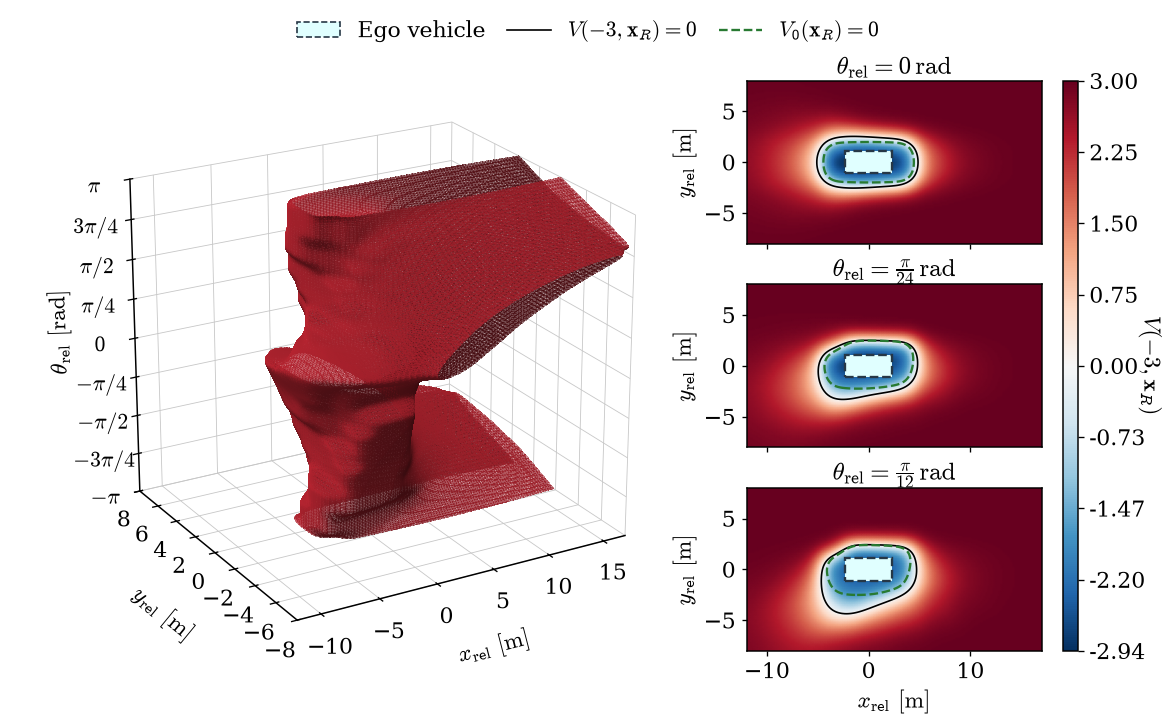

In [27]:
fig_brt = make_angle_figure("BRT")
finish_figure(plt.gcf())
plt.show()


In [28]:
# Imposta True ed esegui questa cella per esportare.
SALVA = True

if SALVA:
    export_figure(
        fig_brt,
        nome="ttc_brt",
        cartella=METRIC,
        formati=("pdf", "eps"),
        sovrascrivi=True,
    )


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_brt.pdf


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as uni

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_brt.eps


## BRT — mosaico 3×3

Contorno BRT nero; contorno V₀ verde tratteggiato. Usa i parametri del mosaico definiti sopra.

Vista precedente: export con suffisso `_old`. Il mosaico aggiornato è nella sezione finale.

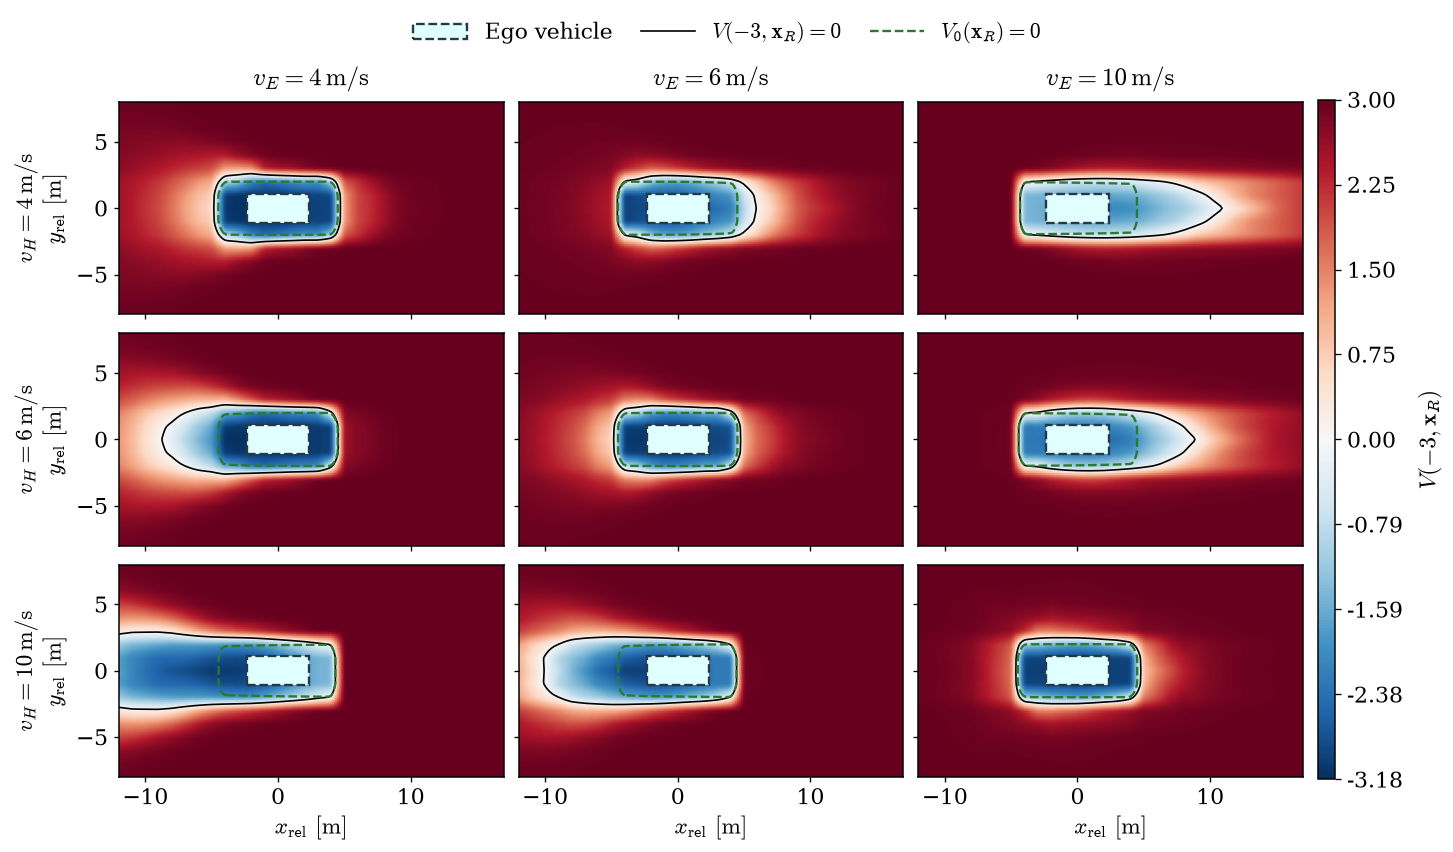

In [29]:
fig_brt_slices = make_speed_mosaic("BRT")
finish_figure(plt.gcf())
plt.show()


In [30]:
# Imposta True ed esegui questa cella per esportare.
SALVA = True

if SALVA:
    export_figure(
        fig_brt_slices,
        nome=("ttc_brt_slices") + "_old",
        cartella=METRIC,
        formati=("pdf", "eps"),
        sovrascrivi=True,
    )


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_brt_slices_old.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very l

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_brt_slices_old.eps


## Mosaici aggiornati per la tesi

Colonne: velocità Ego. Righe: `delta_E`. Velocità Human fissa a 6 m/s. I vecchi mosaici sono conservati nelle celle precedenti ed esportati con suffisso `_old`; questi aggiornati mantengono i nomi di export originali.

In [31]:
from scripts.plot_terminal_slices import make_mosaic

# Configurazione comune dei due nuovi mosaici.
MOSAIC_ROW_PARAMETER = "delta_E"
MOSAIC_ROW_VALUES = (0.0, np.pi/24, np.pi / 12)
MOSAIC_EGO_SPEEDS = (4.0, 6.0, 10.0)
MOSAIC_HUMAN_SPEED = 6.0
MOSAIC_THETA_FIXED = 0.0
MOSAIC_DELTA_FIXED = 0.0
UPDATED_MOSAIC_SIZE = (12.0, 7.0)
UPDATED_MOSAIC_SMOOTHING = 2
UPDATED_MOSAIC_FONT_SIZE = 14
EXPORT_UPDATED_MOSAICS = True
UPDATED_MOSAIC_FORMATS = ("pdf", "eps")

### V0 — mosaico aggiornato

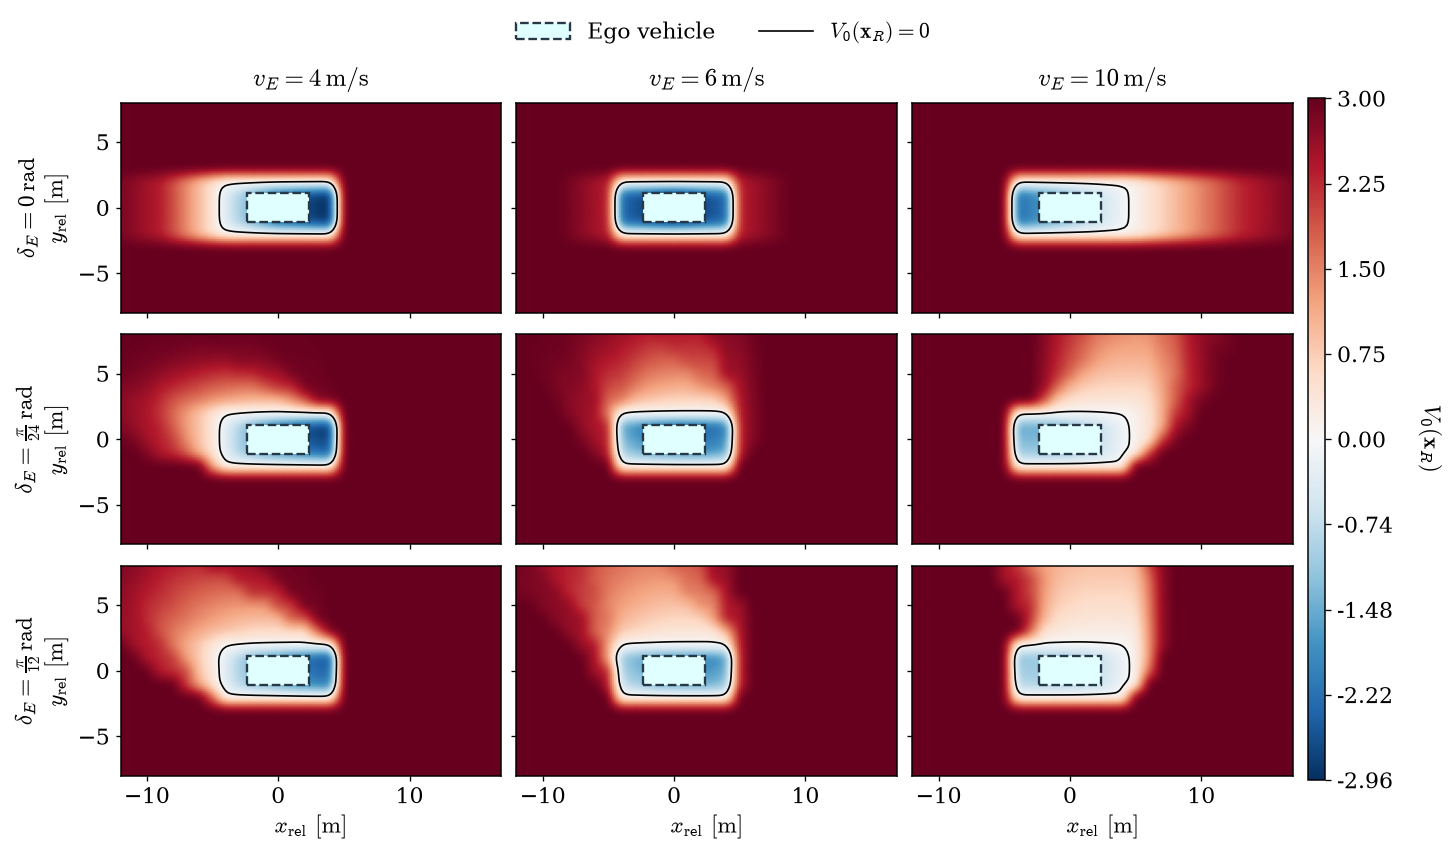

In [32]:
fig_v0_slices_updated = make_mosaic(
    METRIC, "V0",
    data_directory=DATA_DIRECTORY,
    row_parameter=MOSAIC_ROW_PARAMETER,
    row_values=MOSAIC_ROW_VALUES,
    v_h=MOSAIC_HUMAN_SPEED,
    v_e_values=MOSAIC_EGO_SPEEDS,
    theta_rel=MOSAIC_THETA_FIXED,
    delta_e=MOSAIC_DELTA_FIXED,
    figure_size=UPDATED_MOSAIC_SIZE,
    smoothing_sigma=UPDATED_MOSAIC_SMOOTHING,
    font_size=UPDATED_MOSAIC_FONT_SIZE,
)
finish_figure(fig_v0_slices_updated)
plt.show()

In [33]:
if EXPORT_UPDATED_MOSAICS:
    export_figure(
        fig_v0_slices_updated,
        nome="ttc_v0_slices",
        cartella=METRIC,
        formati=UPDATED_MOSAIC_FORMATS,
        sovrascrivi=True,
    )

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_v0_slices.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_v0_slices.eps


### BRT — mosaico aggiornato

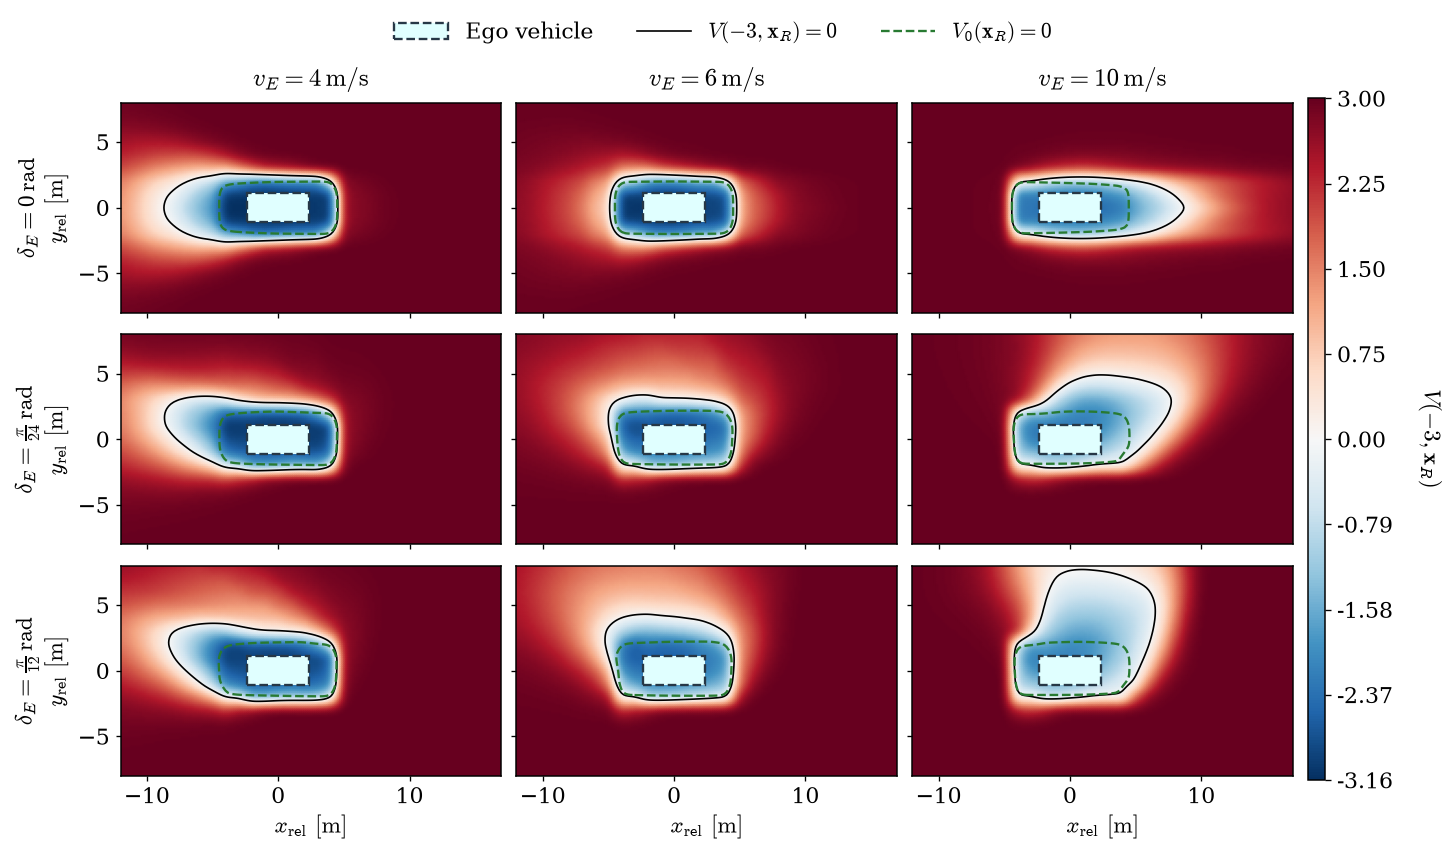

In [34]:
fig_brt_slices_updated = make_mosaic(
    METRIC, "BRT",
    data_directory=DATA_DIRECTORY,
    row_parameter=MOSAIC_ROW_PARAMETER,
    row_values=MOSAIC_ROW_VALUES,
    v_h=MOSAIC_HUMAN_SPEED,
    v_e_values=MOSAIC_EGO_SPEEDS,
    theta_rel=MOSAIC_THETA_FIXED,
    delta_e=MOSAIC_DELTA_FIXED,
    figure_size=UPDATED_MOSAIC_SIZE,
    smoothing_sigma=UPDATED_MOSAIC_SMOOTHING,
    font_size=UPDATED_MOSAIC_FONT_SIZE,
)
finish_figure(fig_brt_slices_updated)
plt.show()

In [35]:
if EXPORT_UPDATED_MOSAICS:
    export_figure(
        fig_brt_slices_updated,
        nome="ttc_brt_slices",
        cartella=METRIC,
        formati=UPDATED_MOSAIC_FORMATS,
        sovrascrivi=True,
    )

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_brt_slices.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very l

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/ttc/ttc_brt_slices.eps
